# Operando Pipeline Runner

Fill in the paths below, then run all cells.

This notebook loads `operando data.py` and `operando plots.py` relative to the `toolbox/operando` folder so it works regardless of where `toolbox` lives.

In [30]:
# Imports
import os
import importlib.util

# Resolve module paths relative to this notebook location
# Assumes this notebook lives in toolbox/operando
notebook_dir = os.path.abspath(os.getcwd())
data_module_path = os.path.join(notebook_dir, "operando data.py")
plots_module_path = os.path.join(notebook_dir, "operando plots.py")

# Load operando data module
data_spec = importlib.util.spec_from_file_location("operando_data", data_module_path)
operando_data = importlib.util.module_from_spec(data_spec)
data_spec.loader.exec_module(operando_data)

# Load operando plots module
plots_spec = importlib.util.spec_from_file_location("operando_plots", plots_module_path)
operando_plots = importlib.util.module_from_spec(plots_spec)
plots_spec.loader.exec_module(operando_plots)

run_operando_pipeline = operando_data.run_operando_pipeline


In [31]:
# === Base directory ===
# Set this to the root folder that contains your data_raw folder
base_dir = r"/data01/Leon_BOA_December2025"

# === Paths under base_dir ===
exp_dir = os.path.join(base_dir, "LiMetal/exp1301_LiMetal_final")
beamhistory_path = os.path.join(base_dir, "LiMetal/Leon_BOA_Dec2025_exp1301_LiMetal_final_1s.csv")
reference_dir = os.path.join(base_dir, "Ref/exp004_Ref1um_NewCell_40x20NA_wmetal")
reference_beamhistory_path = os.path.join(base_dir, "Ref/Leon_BOA_Dec2025_Ref.csv")

echem_folder = os.path.join(base_dir, "EChem_Dec 02-09 2025 (BOA)/6Lithium Metal")
video_output_path = os.path.join(base_dir, "LiMetal/exp1301_LiMetal_final.mp4")

# Optional
output_dir = None  # auto-name with experiment folder
exposure_seconds = 2
uncorrected_output_folder_name = None  # auto-name with experiment folder


In [32]:
# Run pipeline
result = run_operando_pipeline(
    exp_dir=exp_dir,
    beamhistory_path=beamhistory_path,
    output_dir=output_dir,
    exposure_seconds=exposure_seconds,
    reference_dir=reference_dir,
    reference_beamhistory_path=reference_beamhistory_path,
    uncorrected_output_folder_name=uncorrected_output_folder_name,
)

result


{'corrected_dir': '/data01/Leon_BOA_December2025/LiMetal/corrected_tiffs_exp1301_LiMetal_final',
 'uncorrected_dir': '/data01/Leon_BOA_December2025/LiMetal/uncorrected_tiffs_exp1301_LiMetal_final',
 'reference_beam_integral_per_minute': 83389.54284559663}

### The images should have been OB-corrected with the reference image. Before plotting, you may need to manually filter bright spots from TPX hot pixels.

# Plotting and Video

This section loads corrected images, extracts `MeanTPXModifiedTime` from TIFF tags, loads electrochemical data, then creates:
- A potential + image video
- A potential + thickness plot

In [33]:
# Plot/video settings
conv_thickness = 1.0
time_column = "time/s"
fps = 10
dt_seconds = 120
cmap = "inferno"
vmin = None
vmax = None
dpi = 150
merge_minutes = 1
merge_method = "mean"
roi = dict(r0=160, x0=224, y0=219)
potential_ylim=(-0.4, 0.6)

In [34]:
import tifffile
from datetime import datetime

def load_corrected_images_with_time(corrected_dir, tag_id=65002):
    records = []
    for fname in sorted(os.listdir(corrected_dir)):
        path = os.path.join(corrected_dir, fname)
        if not os.path.isfile(path):
            continue
        # Try to open as TIFF (works even if no extension)
        try:
            with tifffile.TiffFile(path) as tif:
                img = tif.asarray()
                tags = tif.pages[0].tags
                if tag_id not in tags:
                    continue
                dt_str = tags[tag_id].value
        except Exception:
            continue

        # Parse datetime
        try:
            dt = datetime.strptime(dt_str, "%Y-%m-%d %H:%M:%S")
        except Exception:
            continue

        records.append((dt, img, path))

    records.sort(key=lambda x: x[0])
    img_datetimes = [r[0] for r in records]
    img_series = [r[1] for r in records]
    paths = [r[2] for r in records]
    return img_datetimes, img_series, paths


In [35]:
# Load corrected images (MeanTPXModifiedTime)
corrected_dir = result["corrected_dir"]
img_datetimes, img_series, img_paths = load_corrected_images_with_time(corrected_dir)
img_datetimes, img_series, img_paths = operando_plots.load_images(
    corrected_dir,
    r0=roi["r0"],
    x0=roi["x0"],
    y0=roi["y0"],
)

# Load electrochemical data
echem_datetimes, potential_series, echem_thickness_series = operando_plots.load_echem_data(
    echem_folder,
    conv_thickness=conv_thickness,
    time_column=time_column,
)

# Optionally merge images in time
img_datetimes, img_series = operando_plots.merge_images_by_time(
    img_datetimes, img_series, merge_minutes=merge_minutes, method=merge_method
)


In [36]:
# Make potential + image video
operando_plots.make_potential_image_video_uniform_time(
    echem_datetimes=echem_datetimes,
    potential_series=potential_series,
    img_datetimes=img_datetimes,
    img_series=img_series,
    output_path=video_output_path,
    fps=fps,
    dt_seconds=dt_seconds,
    dpi=dpi,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    potential_ylim=potential_ylim
)


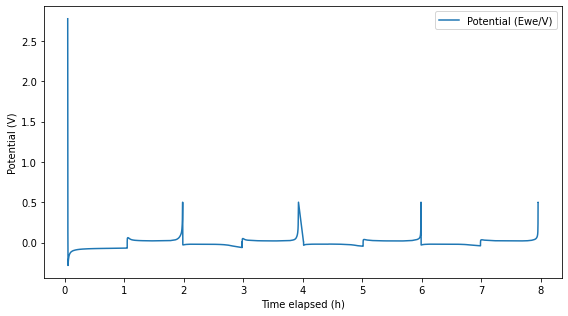

In [16]:
# Make potential + thickness plot (image-derived thickness)
avg_thickness_series = operando_plots.circular_average_thickness_series(
    img_series, **roi
)

operando_plots.plot_potential_and_thickness(
    echem_datetime_series=echem_datetimes,
    potential_series=potential_series,
    echem_thickness_series=echem_thickness_series,
    img_datetime_series=img_datetimes,
    avg_thickness_series=avg_thickness_series,
)
